# Member C: Scratch ResNet-18 and Augmentation Ablation

This notebook contains the complete workflow for Member C in one place. It compares two controlled experiments on the same frozen 500-class dataset:

- **C0:** scratch ResNet-18 without random training augmentation;
- **C1:** scratch ResNet-18 with `RandomResizedCrop(224)` and `RandomHorizontalFlip()`.

The notebook includes data checks, preprocessing, model construction, training, validation-based checkpoint selection, test evaluation, result verification, plots, error analysis, and a live checkpoint inference.

A one-epoch **smoke test** is executed to show that the training pipeline runs inside this notebook. The completed C0/C1 experiments are not trained again by default because they already required long GPU runs. Instead, their checkpoint, history, predictions, and metrics are loaded and cross-checked programmatically. Set `RUN_FULL_TRAINING = True` only when a complete reproduction is intentionally required.

## Workflow inputs, processing, and outputs

| Stage | Main input | Main processing | Main output |
|---|---|---|---|
| Dataset audit | `data_metadata/train.csv`, `val.csv`, `test.csv`, `class_to_idx.json`, and image files | Count classes/images, verify labels and files, and test split overlap | Split audit table and pass/fail assertions |
| Preprocessing | One image path and its class index | RGB conversion, online train augmentation, tensor conversion, and normalization | A normalized `3 x 224 x 224` tensor and label |
| Training/validation | C0 or C1 configuration and DataLoaders | Scratch ResNet-18 optimisation; validation after each epoch | `history.csv`, `best.pt`, `last.pt`, validation metrics and predictions |
| Held-out testing | Frozen best validation checkpoint and `test.csv` | One evaluation pass with deterministic preprocessing | `metrics_test.json`, `predictions_test.csv`, and `confusion_matrix_test.npy` |
| Analysis | Saved histories, metrics, predictions, taxonomy, and checkpoint | Controlled C0/C1 comparison, error grouping, and live inference | Tables, learning curves, selected examples, and a checkpoint prediction check |

Two execution levels are intentionally separated. The **smoke test** uses a tiny subset for one epoch only to verify that the implementation runs. The **formal C0/C1 runs** use all 20,000 training images, 5,000 validation images, and 5,000 held-out test images. Saved formal artifacts are loaded only to reproduce the displayed analysis without repeating multi-hour GPU training.


## 1. Environment and project paths

The notebook can be opened from either the project root or the `notebooks/` folder. Relative paths are resolved automatically. The environment cell also records the Python, PyTorch, CUDA, and GPU information used for this execution.

In [1]:
from __future__ import annotations

import copy
import csv
import gc
import hashlib
import json
import os
import platform
import random
import sys
import time
from pathlib import Path
from typing import Any

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".cache" / "matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True})

# Resolve paths from either the project root or notebooks/ without hard-coding a user folder.
def find_project_root() -> Path:
    candidates = [Path.cwd(), Path.cwd().parent]
    for candidate in candidates:
        if (candidate / "data_metadata" / "train.csv").exists():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from the project "
        "folder or its notebooks/ subfolder."
    )

PROJECT_ROOT = find_project_root()
METADATA_DIR = PROJECT_ROOT / "data_metadata"
DATA_ROOT = PROJECT_ROOT / "dataset_extracted"
# Use the available GPU for formal training, while keeping the notebook CPU-compatible.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 500
SEED = 9517

environment = {
    "project_root": str(PROJECT_ROOT),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}
display(pd.DataFrame(environment.items(), columns=["Item", "Value"]))

,Item,Value
0,project_root,E:\proj9517
1,python,3.10.20
2,platform,Windows-10-10.0.26200-SP0
3,torch,2.12.1+cu132
4,cuda_available,True
5,cuda_runtime,13.2
6,device,cuda
7,gpu,NVIDIA GeForce RTX 4080 Laptop GPU


## 2. Experiment controls

C0 and C1 use the same dataset split, seed, architecture, loss, optimizer, scheduler, batch size, maximum epochs, early stopping rule, and evaluation metrics. The intended experimental variable is the **training transform**.

The flags below prevent an accidental multi-hour training run when somebody selects *Run All*. The smoke test uses only 64 training and 64 validation images for one epoch. It validates the code path but is not a reportable experiment.

In [2]:
# Safe defaults: verify the pipeline quickly and avoid an accidental multi-hour reproduction.
RUN_SMOKE_TEST = True
RUN_FULL_TRAINING = False

# C1 is the reference scratch configuration with the selected random augmentation.
C1_CONFIG = {
    "experiment": {
        "name": "c1_scratch_resnet18_standard_aug",
        "seed": SEED,
        "output_dir": "outputs/c1_scratch_resnet18_standard_aug",
    },
    "data": {
        "root": "dataset_extracted",
        "metadata_dir": "data_metadata",
        "image_size": 224,
        "resize_size": 256,
        "train_transform": "standard",
        "color_jitter": False,
        "max_train_samples": None,
        "max_val_samples": None,
    },
    "model": {
        "architecture": "resnet18",
        "pretrained": False,
        "num_classes": NUM_CLASSES,
    },
    "loader": {"batch_size": 128, "workers": 4, "pin_memory": True},
    "training": {
        "device": "cuda",
        "epochs": 100,
        "amp": True,
        "deterministic": True,
        "grad_accum_steps": 1,
        "optimizer": {
            "name": "sgd",
            "lr": 0.05,
            "momentum": 0.9,
            "weight_decay": 0.0001,
        },
        "scheduler": {"name": "cosine", "t_max": 100, "eta_min": 0.0},
        "early_stopping": {"patience": 15, "min_delta": 0.0001},
    },
}

# Derive C0 from C1 so the training transform is the only intended experimental change.
C0_CONFIG = copy.deepcopy(C1_CONFIG)
C0_CONFIG["experiment"].update(
    name="c0_scratch_resnet18_noaug",
    output_dir="outputs/c0_scratch_resnet18_noaug",
)
C0_CONFIG["data"]["train_transform"] = "noaug"

# The smoke configuration reduces only data volume and duration; it is never reported.
SMOKE_CONFIG = copy.deepcopy(C1_CONFIG)
SMOKE_CONFIG["experiment"].update(
    name="member_c_notebook_smoke",
    output_dir="outputs/member_c_notebook_smoke",
)
SMOKE_CONFIG["data"].update(max_train_samples=64, max_val_samples=64)
SMOKE_CONFIG["loader"].update(batch_size=16, workers=0)
SMOKE_CONFIG["training"].update(epochs=1)
SMOKE_CONFIG["training"]["scheduler"].update(t_max=1)
SMOKE_CONFIG["training"]["early_stopping"].update(patience=1)

comparison = pd.DataFrame(
    [
        {
            "Run": "C0",
            "Initialization": "Scratch (weights=None)",
            "Training transform": "Resize + CenterCrop (no random augmentation)",
        },
        {
            "Run": "C1",
            "Initialization": "Scratch (weights=None)",
            "Training transform": "RandomResizedCrop + RandomHorizontalFlip",
        },
    ]
)
display(comparison)

,Run,Initialization,Training transform
0,C0,Scratch (weights=None),Resize + CenterCrop (no random augmentation)
1,C1,Scratch (weights=None),RandomResizedCrop + RandomHorizontalFlip


## 3. Frozen dataset audit

A separate group member prepared the fixed split. Member C does not create another copy of the dataset. The model reads `train.csv`, `val.csv`, and `test.csv`; each row stores an image path and its 0-based class index.

Important checks here are the number of images, the number of represented classes, equal per-class support, split leakage, valid class indices, and missing image files.

**Input:** the three frozen CSV manifests, class mapping, taxonomy, and image root.  
**Output:** per-split image/class counts, missing-file counts, overlap counts, and assertions that stop execution if the frozen data contract is broken.


In [3]:
split_frames: dict[str, pd.DataFrame] = {}
audit_rows = []
image_id_sets = {}

# Audit every manifest before constructing a model so data faults fail early.
for split in ["train", "val", "test"]:
    frame = pd.read_csv(METADATA_DIR / f"{split}.csv", dtype={"image_id": str})
    split_frames[split] = frame
    image_id_sets[split] = set(frame["image_id"])
    counts = frame["class_index"].value_counts()
    missing_files = sum(
        not (DATA_ROOT / Path(path)).exists() for path in frame["image_path"]
    )
    audit_rows.append(
        {
            "Split": split,
            "Images": len(frame),
            "Classes": frame["class_index"].nunique(),
            "Min/class": int(counts.min()),
            "Max/class": int(counts.max()),
            "Missing files": int(missing_files),
        }
    )

split_audit = pd.DataFrame(audit_rows)
display(split_audit)

# Image IDs must be disjoint across all three splits; test images remain held out.
leakage = {
    "train/val overlap": len(image_id_sets["train"] & image_id_sets["val"]),
    "train/test overlap": len(image_id_sets["train"] & image_id_sets["test"]),
    "val/test overlap": len(image_id_sets["val"] & image_id_sets["test"]),
}
display(pd.DataFrame(leakage.items(), columns=["Check", "Overlapping image IDs"]))

with (METADATA_DIR / "class_to_idx.json").open(encoding="utf-8") as handle:
    class_to_idx = {str(k): int(v) for k, v in json.load(handle).items()}
taxonomy = pd.read_csv(METADATA_DIR / "taxonomy.csv")

# These assertions encode the frozen 500-class, 40/10/10-per-class contract.
assert split_audit.set_index("Split").loc["train", "Images"] == 20_000
assert split_audit.set_index("Split").loc["val", "Images"] == 5_000
assert split_audit.set_index("Split").loc["test", "Images"] == 5_000
assert (split_audit["Classes"] == NUM_CLASSES).all()
assert (split_audit["Missing files"] == 0).all()
assert all(value == 0 for value in leakage.values())
assert sorted(class_to_idx.values()) == list(range(NUM_CLASSES))
print("Dataset audit passed: 30,000 images, 500 classes, no split leakage, no missing files.")

,Split,Images,Classes,Min/class,Max/class,Missing files
0,train,20000,500,40,40,0
1,val,5000,500,10,10,0
2,test,5000,500,10,10,0


,Check,Overlapping image IDs
0,train/val overlap,0
1,train/test overlap,0
2,val/test overlap,0


Dataset audit passed: 30,000 images, 500 classes, no split leakage, no missing files.


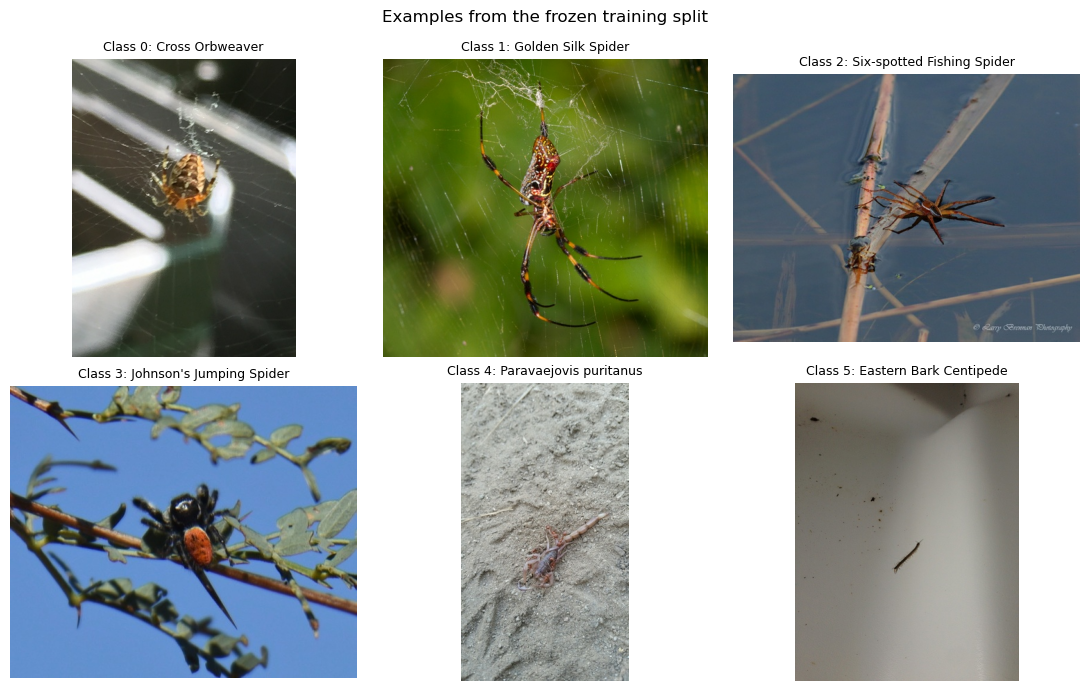

In [4]:
sample_rows = (
    split_frames["train"]
    .sort_values(["class_index", "image_id"])
    .groupby("class_index", as_index=False)
    .head(1)
    .head(6)
)

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for axis, (_, row) in zip(axes.ravel(), sample_rows.iterrows()):
    with Image.open(DATA_ROOT / row["image_path"]) as image:
        axis.imshow(image.convert("RGB"))
    title = row.get("common_name") or row.get("species") or f"Class {row['class_index']}"
    axis.set_title(f"Class {row['class_index']}: {title}", fontsize=9)
    axis.axis("off")
fig.suptitle("Examples from the frozen training split")
fig.tight_layout()
plt.show()

## 4. Data pipeline and augmentation

`ManifestImageDataset` joins the configured image root with `image_path` from the CSV. Training augmentation is applied online each time an image is loaded; no additional processed-image folder is created.

C1 uses random crop and horizontal flip. C0, validation, and test use deterministic resize and centre crop. Both runs use the same ImageNet mean and standard deviation, so normalization is not an experimental variable.

**Input:** one manifest row containing an image path and class index.  
**Output:** a normalized image tensor of shape `3 x 224 x 224`, its integer target, and metadata used later for prediction-level analysis.


In [5]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Images stay on disk; the selected transform is applied online in __getitem__.
class ManifestImageDataset(Dataset):
    def __init__(
        self,
        csv_path: Path,
        data_root: Path,
        transform,
        num_classes: int,
        max_samples: int | None = None,
        sample_seed: int = SEED,
    ) -> None:
        frame = pd.read_csv(csv_path, dtype={"image_id": str})
        required = {"image_path", "image_id", "class_index", "split"}
        missing = required - set(frame.columns)
        if missing:
            raise ValueError(f"{csv_path} is missing columns: {sorted(missing)}")
        expected_split = csv_path.stem
        if set(frame["split"].astype(str)) != {expected_split}:
            raise ValueError(f"Unexpected split values in {csv_path}")
        if max_samples is not None:
            frame = frame.sample(
                n=min(max_samples, len(frame)), random_state=sample_seed
            ).reset_index(drop=True)
        labels = frame["class_index"].astype(int)
        if labels.min() < 0 or labels.max() >= num_classes:
            raise ValueError("A class index falls outside the configured range")
        self.frame = frame
        self.data_root = data_root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.frame.iloc[index]
        relative_path = str(row["image_path"])
        with Image.open(self.data_root / relative_path) as image:
            tensor = self.transform(image.convert("RGB"))
        return {
            "image": tensor,
            "target": int(row["class_index"]),
            "image_path": relative_path,
            "image_id": str(row["image_id"]),
        }

def build_transform(
    mode: str,
    image_size: int = 224,
    resize_size: int = 256,
    use_color_jitter: bool = False,
):
    # ImageNet statistics standardise input scale but do not load pretrained weights.
    normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    if mode == "standard":
        operations: list[Any] = [
            transforms.RandomResizedCrop(image_size),
            transforms.RandomHorizontalFlip(),
        ]
        if use_color_jitter:
            operations.append(
                transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)
            )
        operations.extend([transforms.ToTensor(), normalize])
        return transforms.Compose(operations)
    if mode in {"noaug", "eval"}:
        return transforms.Compose(
            [
                transforms.Resize(resize_size),
                transforms.CenterCrop(image_size),
                transforms.ToTensor(),
                normalize,
            ]
        )
    raise ValueError(f"Unknown transform mode: {mode}")

def seed_worker(worker_id: int) -> None:
    del worker_id
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)

# A seeded generator and worker seeds make shuffle/augmentation order reproducible.
def make_loader(dataset, batch_size, workers, shuffle, seed, pin_memory):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=workers,
        pin_memory=pin_memory,
        persistent_workers=workers > 0,
        worker_init_fn=seed_worker,
        generator=generator,
    )

print("Dataset, transform and DataLoader code is ready.")

Dataset, transform and DataLoader code is ready.


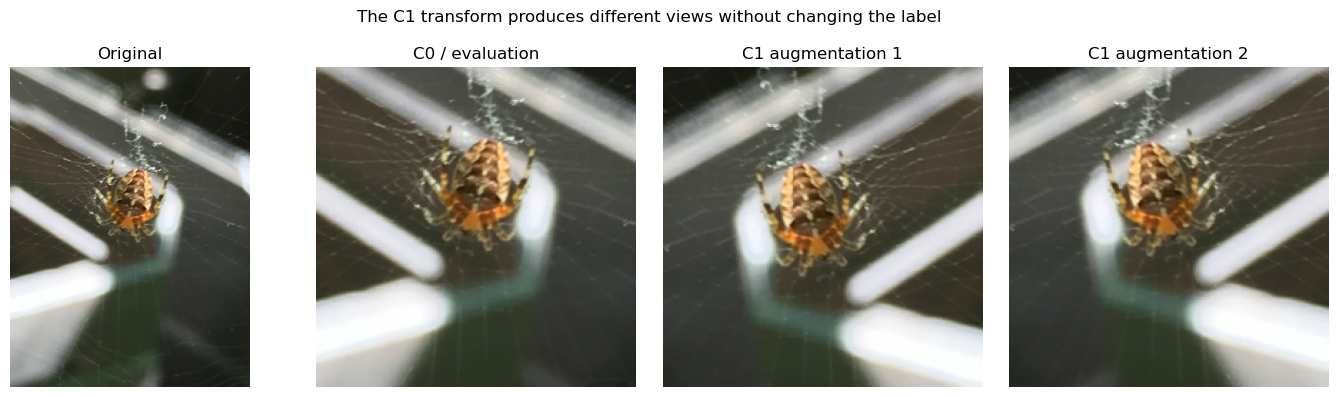

In [6]:
def denormalize(tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    image = tensor.cpu() * std + mean
    return image.clamp(0, 1).permute(1, 2, 0).numpy()

example_path = DATA_ROOT / sample_rows.iloc[0]["image_path"]
with Image.open(example_path) as image:
    example_image = image.convert("RGB")
    eval_tensor = build_transform("eval")(example_image)
    aug_tensor_1 = build_transform("standard")(example_image)
    aug_tensor_2 = build_transform("standard")(example_image)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(example_image)
axes[0].set_title("Original")
axes[1].imshow(denormalize(eval_tensor))
axes[1].set_title("C0 / evaluation")
axes[2].imshow(denormalize(aug_tensor_1))
axes[2].set_title("C1 augmentation 1")
axes[3].imshow(denormalize(aug_tensor_2))
axes[3].set_title("C1 augmentation 2")
for axis in axes:
    axis.axis("off")
fig.suptitle("The C1 transform produces different views without changing the label")
fig.tight_layout()
plt.show()

## 5. Scratch ResNet-18 and evaluation metrics

Both experiments use `weights=None`; therefore, all ResNet-18 parameters start from random initialization. The original ImageNet classification head is replaced by a 500-class linear layer.

Metrics are calculated from raw logits. Top-1 uses `argmax`; Top-5 checks whether the true class is among the five largest logits. Macro precision, recall, and F1 give every class equal weight, which is appropriate for this balanced 500-class split.

**Input:** an image batch and its targets.  
**Output:** 500-class logits together with Top-1, Top-5, macro precision, macro recall, macro-F1, and a 500 x 500 confusion matrix.


In [7]:
# Control Python, NumPy, CPU, and CUDA randomness for the C0/C1 comparison.
def set_seed(seed: int, deterministic: bool = True) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic

def build_model(architecture: str, num_classes: int, pretrained: bool) -> nn.Module:
    if architecture != "resnet18":
        raise ValueError(f"Unsupported architecture: {architecture}")
    if pretrained:
        raise ValueError("Member C must use scratch initialization (pretrained=False)")
    # weights=None is the key condition: no ImageNet parameters enter the scratch baseline.
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

def classification_metrics(targets, logits, num_classes):
    targets = targets.cpu().long()
    logits = logits.cpu().float()
    predicted = logits.argmax(dim=1)
    top5 = logits.topk(k=min(5, num_classes), dim=1).indices
    # Build the confusion matrix once, then derive class-balanced macro metrics from it.
    matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    np.add.at(matrix, (targets.numpy(), predicted.numpy()), 1)
    true_positives = np.diag(matrix).astype(np.float64)
    predicted_counts = matrix.sum(axis=0)
    true_counts = matrix.sum(axis=1)
    precision = np.divide(
        true_positives,
        predicted_counts,
        out=np.zeros_like(true_positives),
        where=predicted_counts != 0,
    )
    recall = np.divide(
        true_positives,
        true_counts,
        out=np.zeros_like(true_positives),
        where=true_counts != 0,
    )
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(true_positives),
        where=(precision + recall) != 0,
    )
    return {
        "top1_accuracy": float((predicted == targets).float().mean()),
        "top5_accuracy": float(
            (top5 == targets.unsqueeze(1)).any(dim=1).float().mean()
        ),
        "macro_precision": float(precision.mean()),
        "macro_recall": float(recall.mean()),
        "macro_f1": float(f1.mean()),
    }, matrix

def prediction_frame(metadata, targets, logits):
    scores = logits.cpu().float()
    targets = targets.cpu().long()
    probabilities = scores.softmax(dim=1)
    predicted = scores.argmax(dim=1)
    predicted_confidence = probabilities.gather(
        1, predicted.unsqueeze(1)
    ).squeeze(1)
    top5 = scores.topk(k=min(5, scores.shape[1]), dim=1).indices
    # Keep predicted_class and the first displayed Top-5 class aligned
    # when argmax/topk resolve an exact tie differently.
    matches = top5.eq(predicted.unsqueeze(1))
    positions = matches.to(torch.int64).argmax(dim=1)
    rows = torch.arange(top5.shape[0])
    swap_rows = rows[matches.any(dim=1) & positions.ne(0)]
    if len(swap_rows):
        swap_positions = positions[swap_rows]
        former_first = top5[swap_rows, 0].clone()
        top5[swap_rows, 0] = predicted[swap_rows]
        top5[swap_rows, swap_positions] = former_first
    top5_confidence = probabilities.gather(1, top5)
    rows = []
    for index, item in enumerate(metadata):
        rows.append(
            {
                "image_path": item["image_path"],
                "image_id": item["image_id"],
                "true_class": int(targets[index]),
                "predicted_class": int(predicted[index]),
                "confidence": float(predicted_confidence[index]),
                "is_correct": int(predicted[index]) == int(targets[index]),
                "top5_classes": json.dumps(top5[index].tolist()),
                "top5_confidences": json.dumps(top5_confidence[index].tolist()),
            }
        )
    return pd.DataFrame(rows)

set_seed(SEED)
model_check = build_model("resnet18", NUM_CLASSES, pretrained=False)
parameter_count = sum(parameter.numel() for parameter in model_check.parameters())
trainable_count = sum(
    parameter.numel() for parameter in model_check.parameters() if parameter.requires_grad
)
print(model_check.fc)
print(f"Parameters: {parameter_count:,}; trainable: {trainable_count:,}")
del model_check

Linear(in_features=512, out_features=500, bias=True)
Parameters: 11,433,012; trainable: 11,433,012


## 6. Training and evaluation engine

The following cells contain the complete training path rather than hiding it in external project modules. Mixed precision is enabled on CUDA. After every epoch, the model is evaluated on validation data. The best checkpoint is selected by validation macro-F1, and early stopping terminates training after 15 non-improving epochs.

Test data is not used inside the training loop. It is evaluated only after the model and configuration are frozen.

**Input:** a C0/C1 configuration, training DataLoader, and validation DataLoader.  
**Output:** epoch history, best/last checkpoints, validation metrics, validation predictions, a confusion matrix, and training curves inside the run directory.


In [8]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    grad_accum_steps,
    amp_enabled,
):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    total_loss = 0.0
    total_examples = 0
    top1_correct = 0
    top5_correct = 0
    started = time.perf_counter()

    for step, batch in enumerate(loader):
        images = batch["image"].to(device, non_blocking=True)
        targets = batch["target"].to(device, non_blocking=True)
        # Autocast accelerates CUDA training; GradScaler below protects gradient precision.
        with torch.autocast(device_type=device.type, enabled=amp_enabled):
            logits = model(images)
            loss = criterion(logits, targets)
            scaled_loss = loss / grad_accum_steps
        scaler.scale(scaled_loss).backward()

        should_step = (
            (step + 1) % grad_accum_steps == 0 or step + 1 == len(loader)
        )
        if should_step:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        count = targets.shape[0]
        total_examples += count
        total_loss += float(loss.detach()) * count
        top5 = logits.detach().topk(k=min(5, logits.shape[1]), dim=1).indices
        top1_correct += int((logits.detach().argmax(dim=1) == targets).sum())
        top5_correct += int((top5 == targets.unsqueeze(1)).any(dim=1).sum())

    if device.type == "cuda":
        torch.cuda.synchronize()
    return {
        "loss": total_loss / total_examples,
        "top1_accuracy": top1_correct / total_examples,
        "top5_accuracy": top5_correct / total_examples,
        "seconds": time.perf_counter() - started,
    }

# Evaluation disables gradients and never updates model parameters.
@torch.inference_mode()
def evaluate_loader(model, loader, criterion, device, amp_enabled):
    model.eval()
    total_loss = 0.0
    total_examples = 0
    targets_parts = []
    logits_parts = []
    metadata = []
    started = time.perf_counter()

    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        targets = batch["target"].to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=amp_enabled):
            logits = model(images)
            loss = criterion(logits, targets)
        count = targets.shape[0]
        total_examples += count
        total_loss += float(loss) * count
        targets_parts.append(targets.cpu())
        logits_parts.append(logits.float().cpu())
        metadata.extend(
            {"image_path": path, "image_id": image_id}
            for path, image_id in zip(batch["image_path"], batch["image_id"])
        )

    if device.type == "cuda":
        torch.cuda.synchronize()
    return (
        total_loss / total_examples,
        torch.cat(targets_parts),
        torch.cat(logits_parts),
        metadata,
        time.perf_counter() - started,
    )

def build_optimizer(model, config):
    name = config["name"].lower()
    if name == "sgd":
        return torch.optim.SGD(
            model.parameters(),
            lr=float(config["lr"]),
            momentum=float(config.get("momentum", 0.9)),
            weight_decay=float(config.get("weight_decay", 0.0)),
        )
    if name == "adamw":
        return torch.optim.AdamW(
            model.parameters(),
            lr=float(config["lr"]),
            weight_decay=float(config.get("weight_decay", 0.0)),
        )
    raise ValueError(f"Unsupported optimizer: {name}")

def build_scheduler(optimizer, config):
    if config["name"] == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=int(config["t_max"]),
            eta_min=float(config.get("eta_min", 0.0)),
        )
    raise ValueError(f"Unsupported scheduler: {config['name']}")

print("Training and evaluation loops are ready.")

Training and evaluation loops are ready.


In [9]:
def resolve_path(value: str | Path) -> Path:
    path = Path(value)
    return path if path.is_absolute() else PROJECT_ROOT / path

def save_json(data, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as handle:
        json.dump(data, handle, indent=2, ensure_ascii=False)
        handle.write("\n")

def save_yaml(data, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as handle:
        yaml.safe_dump(data, handle, sort_keys=False, allow_unicode=True)

def save_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    scaler,
    epoch,
    best_metric,
    stale_epochs,
    config,
    mapping,
):
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "epoch": epoch,
            "best_metric": best_metric,
            "stale_epochs": stale_epochs,
            "config": config,
            "class_to_idx": mapping,
        },
        path,
    )

def save_evaluation_outputs(output_dir, split, metrics, matrix, predictions):
    save_json(metrics, output_dir / f"metrics_{split}.json")
    np.save(output_dir / f"confusion_matrix_{split}.npy", matrix)
    predictions.to_csv(output_dir / f"predictions_{split}.csv", index=False)

def plot_history(history: pd.DataFrame, output_path: Path | None = None):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["val_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[1].plot(history["epoch"], history["train_top1"], label="train")
    axes[1].plot(history["epoch"], history["val_top1"], label="validation")
    axes[1].set_title("Top-1 accuracy")
    axes[2].plot(history["epoch"], history["val_macro_f1"], label="validation")
    axes[2].set_title("Validation macro-F1")
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.legend()
    fig.tight_layout()
    if output_path is not None:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=180, bbox_inches="tight")
    return fig

def build_datasets_and_loaders(config):
    data_cfg = config["data"]
    loader_cfg = config["loader"]
    metadata_dir = resolve_path(data_cfg["metadata_dir"])
    data_root = resolve_path(data_cfg["root"])
    train_transform = build_transform(
        data_cfg["train_transform"],
        data_cfg["image_size"],
        data_cfg["resize_size"],
        data_cfg.get("color_jitter", False),
    )
    eval_transform = build_transform(
        "eval", data_cfg["image_size"], data_cfg["resize_size"], False
    )
    train_dataset = ManifestImageDataset(
        metadata_dir / "train.csv",
        data_root,
        train_transform,
        config["model"]["num_classes"],
        data_cfg.get("max_train_samples"),
        config["experiment"]["seed"],
    )
    val_dataset = ManifestImageDataset(
        metadata_dir / "val.csv",
        data_root,
        eval_transform,
        config["model"]["num_classes"],
        data_cfg.get("max_val_samples"),
        config["experiment"]["seed"],
    )
    common = {
        "batch_size": loader_cfg["batch_size"],
        "workers": loader_cfg["workers"],
        "seed": config["experiment"]["seed"],
        "pin_memory": loader_cfg.get("pin_memory", DEVICE.type == "cuda"),
    }
    return (
        train_dataset,
        val_dataset,
        make_loader(train_dataset, shuffle=True, **common),
        make_loader(val_dataset, shuffle=False, **common),
    )

def run_experiment(config):
    config = copy.deepcopy(config)
    output_dir = resolve_path(config["experiment"]["output_dir"])
    # Never overwrite a formal run: an existing directory may contain report evidence.
    if output_dir.exists():
        raise FileExistsError(
            f"Refusing to overwrite {output_dir}. Use a new output_dir or remove it manually."
        )
    output_dir.mkdir(parents=True)
    (output_dir / "checkpoints").mkdir()
    (output_dir / "plots").mkdir()
    save_yaml(config, output_dir / "config.yaml")

    seed = int(config["experiment"]["seed"])
    set_seed(seed, bool(config["training"].get("deterministic", True)))
    requested_device = config["training"].get("device", "auto")
    device = torch.device(
        "cuda" if requested_device == "auto" and torch.cuda.is_available() else requested_device
    )
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is not available")
    amp_enabled = bool(config["training"].get("amp", True)) and device.type == "cuda"
    train_dataset, val_dataset, train_loader, val_loader = build_datasets_and_loaders(config)

    # Reset immediately before construction so C0/C1 start comparably.
    set_seed(seed, bool(config["training"].get("deterministic", True)))
    model = build_model(**config["model"]).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = build_optimizer(model, config["training"]["optimizer"])
    scheduler = build_scheduler(optimizer, config["training"]["scheduler"])
    scaler = torch.amp.GradScaler(device.type, enabled=amp_enabled)

    best_metric = float("-inf")
    stale_epochs = 0
    history_rows = []
    patience = int(config["training"]["early_stopping"]["patience"])
    min_delta = float(config["training"]["early_stopping"].get("min_delta", 0.0))

    for epoch in range(1, int(config["training"]["epochs"]) + 1):
        train_stats = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler,
            device,
            int(config["training"].get("grad_accum_steps", 1)),
            amp_enabled,
        )
        val_loss, targets, logits, _, val_seconds = evaluate_loader(
            model, val_loader, criterion, device, amp_enabled
        )
        val_metrics, _ = classification_metrics(
            targets, logits, config["model"]["num_classes"]
        )
        row = {
            "epoch": epoch,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "train_loss": train_stats["loss"],
            "train_top1": train_stats["top1_accuracy"],
            "train_top5": train_stats["top5_accuracy"],
            "val_loss": val_loss,
            "val_top1": val_metrics["top1_accuracy"],
            "val_top5": val_metrics["top5_accuracy"],
            "val_macro_precision": val_metrics["macro_precision"],
            "val_macro_recall": val_metrics["macro_recall"],
            "val_macro_f1": val_metrics["macro_f1"],
            "train_seconds": train_stats["seconds"],
            "val_seconds": val_seconds,
        }
        history_rows.append(row)
        pd.DataFrame(history_rows).to_csv(output_dir / "history.csv", index=False)

        # Model selection uses validation macro-F1 only; test labels are not consulted here.
        improved = val_metrics["macro_f1"] > best_metric + min_delta
        if improved:
            best_metric = val_metrics["macro_f1"]
            stale_epochs = 0
            save_checkpoint(
                output_dir / "checkpoints" / "best.pt",
                model,
                optimizer,
                scheduler,
                scaler,
                epoch,
                best_metric,
                stale_epochs,
                config,
                class_to_idx,
            )
        else:
            stale_epochs += 1

        scheduler.step()
        save_checkpoint(
            output_dir / "checkpoints" / "last.pt",
            model,
            optimizer,
            scheduler,
            scaler,
            epoch,
            best_metric,
            stale_epochs,
            config,
            class_to_idx,
        )
        print(
            f"epoch={epoch} train_loss={row['train_loss']:.4f} "
            f"val_loss={val_loss:.4f} val_top1={row['val_top1']:.4f} "
            f"val_macro_f1={row['val_macro_f1']:.4f}"
        )
        # Stop after the configured number of validation epochs without meaningful gain.
        if stale_epochs >= patience:
            print(f"early_stopping epoch={epoch} patience={patience}")
            break

    history = pd.DataFrame(history_rows)
    figure = plot_history(history, output_dir / "plots" / "training_curves.png")
    plt.close(figure)

    checkpoint = torch.load(
        output_dir / "checkpoints" / "best.pt", map_location=device, weights_only=False
    )
    model.load_state_dict(checkpoint["model"])
    val_loss, targets, logits, metadata, _ = evaluate_loader(
        model, val_loader, criterion, device, amp_enabled
    )
    metrics, matrix = classification_metrics(
        targets, logits, config["model"]["num_classes"]
    )
    metrics["loss"] = val_loss
    save_evaluation_outputs(
        output_dir,
        "val",
        metrics,
        matrix,
        prediction_frame(metadata, targets, logits),
    )
    return output_dir

# Load the validation-selected best checkpoint before the single held-out test pass.
def evaluate_frozen_run(run_dir: Path, split: str = "test"):
    with (run_dir / "config.yaml").open(encoding="utf-8") as handle:
        config = yaml.safe_load(handle)
    device = DEVICE
    amp_enabled = bool(config["training"].get("amp", True)) and device.type == "cuda"
    model = build_model(**config["model"]).to(device)
    checkpoint = torch.load(
        run_dir / "checkpoints" / "best.pt", map_location=device, weights_only=False
    )
    model.load_state_dict(checkpoint["model"])
    dataset = ManifestImageDataset(
        resolve_path(config["data"]["metadata_dir"]) / f"{split}.csv",
        resolve_path(config["data"]["root"]),
        build_transform(
            "eval",
            config["data"]["image_size"],
            config["data"]["resize_size"],
            False,
        ),
        config["model"]["num_classes"],
        None,
        config["experiment"]["seed"],
    )
    loader = make_loader(
        dataset,
        config["loader"]["batch_size"],
        config["loader"]["workers"],
        False,
        config["experiment"]["seed"],
        config["loader"].get("pin_memory", device.type == "cuda"),
    )
    criterion = nn.CrossEntropyLoss()
    loss, targets, logits, metadata, _ = evaluate_loader(
        model, loader, criterion, device, amp_enabled
    )
    metrics, matrix = classification_metrics(
        targets, logits, config["model"]["num_classes"]
    )
    metrics["loss"] = loss
    save_evaluation_outputs(
        run_dir,
        split,
        metrics,
        matrix,
        prediction_frame(metadata, targets, logits),
    )
    return metrics

print("Artifact saving, experiment runner, and frozen test evaluator are ready.")

Artifact saving, experiment runner, and frozen test evaluator are ready.


## 7. Executable smoke test

This is a real one-epoch training run through the notebook implementation. It confirms that the data, model, optimizer, mixed precision, validation, checkpoint, history, and output saving work together. It is intentionally too small to be used as an experimental result.

**Input:** 64 sampled training images, 64 sampled validation images, and the C1 pipeline.  
**Output:** a separate one-epoch smoke directory used only as implementation evidence; its accuracy is not reported as a graded result.


In [10]:
# Keep smoke artifacts isolated so they cannot be mistaken for C0/C1 results.
smoke_dir = resolve_path(SMOKE_CONFIG["experiment"]["output_dir"])
if RUN_SMOKE_TEST:
    if not smoke_dir.exists():
        smoke_dir = run_experiment(SMOKE_CONFIG)
        print(f"Smoke test completed: {smoke_dir}")
    else:
        print(f"Existing smoke output reused: {smoke_dir}")
        print("Delete this folder manually if a fresh smoke run is required.")
    smoke_history = pd.read_csv(smoke_dir / "history.csv")
    with (smoke_dir / "metrics_val.json").open(encoding="utf-8") as handle:
        smoke_metrics = json.load(handle)
    display(smoke_history)
    display(pd.DataFrame([smoke_metrics]))
else:
    print("Smoke test disabled by RUN_SMOKE_TEST=False")

epoch=1 train_loss=6.4443 val_loss=60.3400 val_top1=0.0000 val_macro_f1=0.0000


Smoke test completed: E:\proj9517\outputs\member_c_notebook_smoke


,epoch,learning_rate,train_loss,train_top1,train_top5,val_loss,val_top1,val_top5,val_macro_precision,val_macro_recall,val_macro_f1,train_seconds,val_seconds
0,1,0.05,6.444336,0.015625,0.03125,60.339966,0.0,0.015625,0.0,0.0,0.0,0.885732,0.255927


,top1_accuracy,top5_accuracy,macro_precision,macro_recall,macro_f1,loss
0,0.0,0.015625,0.0,0.0,0.0,60.339966


## 8. Optional complete C0/C1 reproduction

The code below is the actual full-training entry point. It is disabled by default because the formal experiments have already been completed and verified. When deliberately enabled, it writes to new reproduction directories rather than overwriting the frozen results.

After training, test evaluation is called once on the best validation checkpoint. This preserves the separation between model selection and final testing.

**Input:** the complete frozen training and validation manifests.  
**Output:** new C0/C1 reproduction directories followed by one held-out test evaluation of each best validation checkpoint.


In [11]:
# Full reproduction deliberately uses new directories and leaves frozen formal runs untouched.
if RUN_FULL_TRAINING:
    reproduction_c1 = copy.deepcopy(C1_CONFIG)
    reproduction_c0 = copy.deepcopy(C0_CONFIG)
    reproduction_c1["experiment"]["output_dir"] = "outputs/notebook_reproduction_c1"
    reproduction_c0["experiment"]["output_dir"] = "outputs/notebook_reproduction_c0"

    c1_new_dir = run_experiment(reproduction_c1)
    c0_new_dir = run_experiment(reproduction_c0)
    print("C1 test:", evaluate_frozen_run(c1_new_dir, "test"))
    print("C0 test:", evaluate_frozen_run(c0_new_dir, "test"))
else:
    print(
        "Full C0/C1 training was not repeated. Set RUN_FULL_TRAINING=True "
        "only for an intentional multi-hour reproduction."
    )

Full C0/C1 training was not repeated. Set RUN_FULL_TRAINING=True only for an intentional multi-hour reproduction.


## 9. Formal artifact provenance checks

The next cell establishes that the displayed formal results are not manually pasted numbers. For each run it checks the saved configuration, checkpoint, class mapping, best epoch, prediction-level metrics, and file hash.

The main metrics are recomputed directly from all 5,000 rows of `predictions_test.csv` and compared with `metrics_test.json`. A maximum error below `1e-6` is accepted to allow normal float32 serialization differences.

**Input:** saved formal configs, histories, checkpoints, class mappings, test metrics, and all 5,000 prediction rows per run.  
**Output:** a provenance table showing best epoch, prediction count, metric agreement, and checkpoint hash; execution stops if any required check fails.


In [12]:
FORMAL_RUNS = {
    "C0: no random augmentation": resolve_path(C0_CONFIG["experiment"]["output_dir"]),
    "C1: standard augmentation": resolve_path(C1_CONFIG["experiment"]["output_dir"]),
}

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Recompute metrics from every prediction row instead of trusting displayed summary numbers.
def recompute_metrics_from_predictions(frame: pd.DataFrame, num_classes=NUM_CLASSES):
    true = frame["true_class"].to_numpy(dtype=np.int64)
    pred = frame["predicted_class"].to_numpy(dtype=np.int64)
    top5_lists = frame["top5_classes"].map(json.loads)
    matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    np.add.at(matrix, (true, pred), 1)
    tp = np.diag(matrix).astype(np.float64)
    predicted_counts = matrix.sum(axis=0)
    true_counts = matrix.sum(axis=1)
    precision = np.divide(
        tp, predicted_counts, out=np.zeros_like(tp), where=predicted_counts != 0
    )
    recall = np.divide(
        tp, true_counts, out=np.zeros_like(tp), where=true_counts != 0
    )
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(tp),
        where=(precision + recall) != 0,
    )
    return {
        "top1_accuracy": float((true == pred).mean()),
        "top5_accuracy": float(
            np.mean([int(target in values) for target, values in zip(true, top5_lists)])
        ),
        "macro_precision": float(precision.mean()),
        "macro_recall": float(recall.mean()),
        "macro_f1": float(f1.mean()),
    }

provenance_rows = []
formal_artifacts = {}
# Cross-check each saved run against its config, checkpoint, mapping, history, and predictions.
for run_name, run_dir in FORMAL_RUNS.items():
    with (run_dir / "config.yaml").open(encoding="utf-8") as handle:
        saved_config = yaml.safe_load(handle)
    with (run_dir / "metrics_test.json").open(encoding="utf-8") as handle:
        saved_test_metrics = json.load(handle)
    history = pd.read_csv(run_dir / "history.csv")
    predictions = pd.read_csv(run_dir / "predictions_test.csv")
    checkpoint_path = run_dir / "checkpoints" / "best.pt"
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    recomputed = recompute_metrics_from_predictions(predictions)
    maximum_error = max(
        abs(float(saved_test_metrics[key]) - value)
        for key, value in recomputed.items()
    )
    history_best_epoch = int(
        history.loc[history["val_macro_f1"].idxmax(), "epoch"]
    )
    checks = {
        "scratch": saved_config["model"]["pretrained"] is False,
        "architecture": saved_config["model"]["architecture"] == "resnet18",
        "500 classes": int(saved_config["model"]["num_classes"]) == NUM_CLASSES,
        "best epoch": int(checkpoint["epoch"]) == history_best_epoch,
        "checkpoint config": checkpoint["config"] == saved_config,
        "class mapping": checkpoint["class_to_idx"] == class_to_idx,
        "metrics reproduced": maximum_error < 1e-6,
    }
    provenance_rows.append(
        {
            "Run": run_name,
            "Train transform": saved_config["data"]["train_transform"],
            "Best epoch": int(checkpoint["epoch"]),
            "Predictions": len(predictions),
            "Max metric error": maximum_error,
            "All checks": all(checks.values()),
            "Checkpoint SHA256 (first 12)": sha256_file(checkpoint_path)[:12],
        }
    )
    formal_artifacts[run_name] = {
        "config": saved_config,
        "metrics": saved_test_metrics,
        "history": history,
        "predictions": predictions,
        "checkpoint_path": checkpoint_path,
        "checks": checks,
    }
    del checkpoint
    gc.collect()

provenance_table = pd.DataFrame(provenance_rows)
display(provenance_table)
assert provenance_table["All checks"].all(), "A formal artifact check failed"
print("All formal artifact checks passed. Full retraining is not required.")

,Run,Train transform,Best epoch,Predictions,Max metric error,All checks,Checkpoint SHA256 (first 12)
0,C0: no random augmentation,noaug,21,5000,8.440018e-09,True,33bc5f0f9558
1,C1: standard augmentation,standard,87,5000,1.277924e-08,True,8578fedfb024


All formal artifact checks passed. Full retraining is not required.


## 10. Learning curves and controlled test comparison

The plots below are regenerated from `history.csv`, not imported as screenshots. C1 is compared with C0 using the same axes. Different stopping epochs are expected because early stopping depends on validation macro-F1.

**Input:** the two formal `history.csv` and `metrics_test.json` files.  
**Output:** aligned validation curves, the complete C0/C1 metric table, and percentage-point improvements.


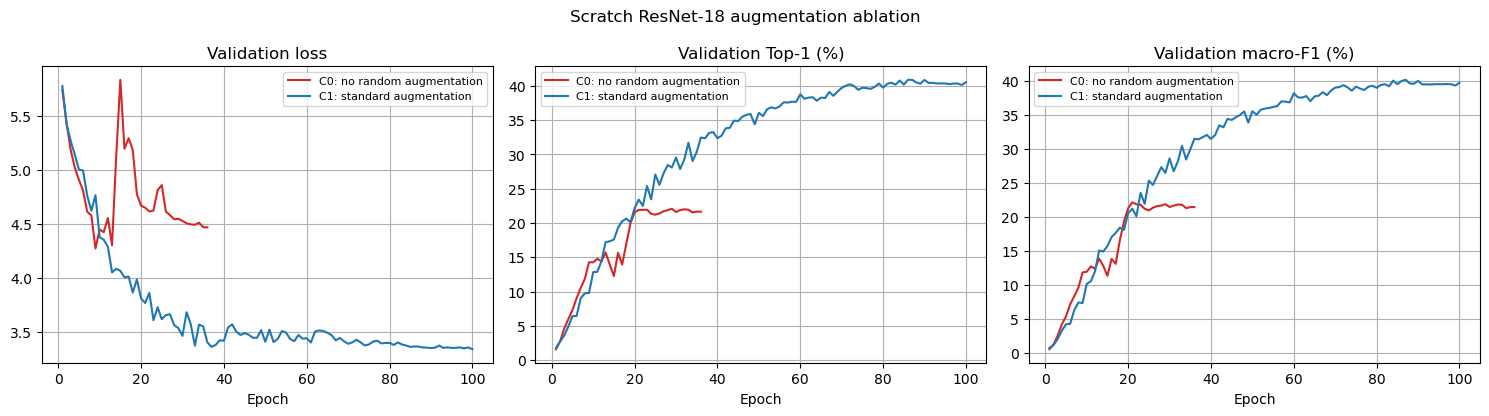

,Top-1 (%),Top-5 (%),Macro precision (%),Macro recall (%),Macro-F1 (%)
Run,,,,,
C0: no random augmentation,21.62,44.24,23.82,21.62,21.42
C1: standard augmentation,41.32,64.16,41.40,41.32,40.45


,Top-1 (%),Top-5 (%),Macro precision (%),Macro recall (%),Macro-F1 (%)
C1 - C0 (percentage points),19.7,19.92,17.59,19.7,19.03


In [13]:
colors = {
    "C0: no random augmentation": "#d62728",
    "C1: standard augmentation": "#1f77b4",
}
# Regenerate aligned plots from history.csv rather than importing result screenshots.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for run_name, artifact in formal_artifacts.items():
    history = artifact["history"]
    axes[0].plot(history["epoch"], history["val_loss"], label=run_name, color=colors[run_name])
    axes[1].plot(history["epoch"], history["val_top1"] * 100, label=run_name, color=colors[run_name])
    axes[2].plot(history["epoch"], history["val_macro_f1"] * 100, label=run_name, color=colors[run_name])
axes[0].set_title("Validation loss")
axes[1].set_title("Validation Top-1 (%)")
axes[2].set_title("Validation macro-F1 (%)")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.legend(fontsize=8)
fig.suptitle("Scratch ResNet-18 augmentation ablation")
fig.tight_layout()
plt.show()

result_rows = []
for run_name, artifact in formal_artifacts.items():
    metrics = artifact["metrics"]
    result_rows.append(
        {
            "Run": run_name,
            "Top-1 (%)": metrics["top1_accuracy"] * 100,
            "Top-5 (%)": metrics["top5_accuracy"] * 100,
            "Macro precision (%)": metrics["macro_precision"] * 100,
            "Macro recall (%)": metrics["macro_recall"] * 100,
            "Macro-F1 (%)": metrics["macro_f1"] * 100,
        }
    )
result_table = pd.DataFrame(result_rows).set_index("Run")
display(result_table.round(2))

c0 = result_table.loc["C0: no random augmentation"]
c1 = result_table.loc["C1: standard augmentation"]
delta = (c1 - c0).rename("C1 - C0 (percentage points)").to_frame().T
display(delta.round(2))

## 11. Prediction-level error analysis

Aggregate metrics do not show which organisms are confused. The next cells attach taxonomy names to C1 predictions, list frequent confusion pairs, and show a small number of high-confidence correct and incorrect examples. These examples are selected by an explicit rule rather than manually chosen to support a claim.

**Input:** corrected C1 test predictions and the taxonomy table.  
**Output:** frequent directed confusion pairs and a rule-selected grid of high-confidence correct and incorrect examples.


,True label,Predicted label,Count
440,Spring Azure,Mazarine Blue,5
827,Imperial Eagle,European Honey-buzzard,5
855,Smew,Common Merganser,4
454,Marine Blue,Mazarine Blue,3
637,Chrysopa oculata,Australian Green Mantis,3
847,Mute Swan,Dalmatian Pelican,3
986,Alpine Chough,Black Crake,3
1224,Warbling White-eye,White-plumed Honeyeater,3
1231,Indian White-eye,Hooded Warbler,3
1738,giant white fawn lily,spring spiderlily,3


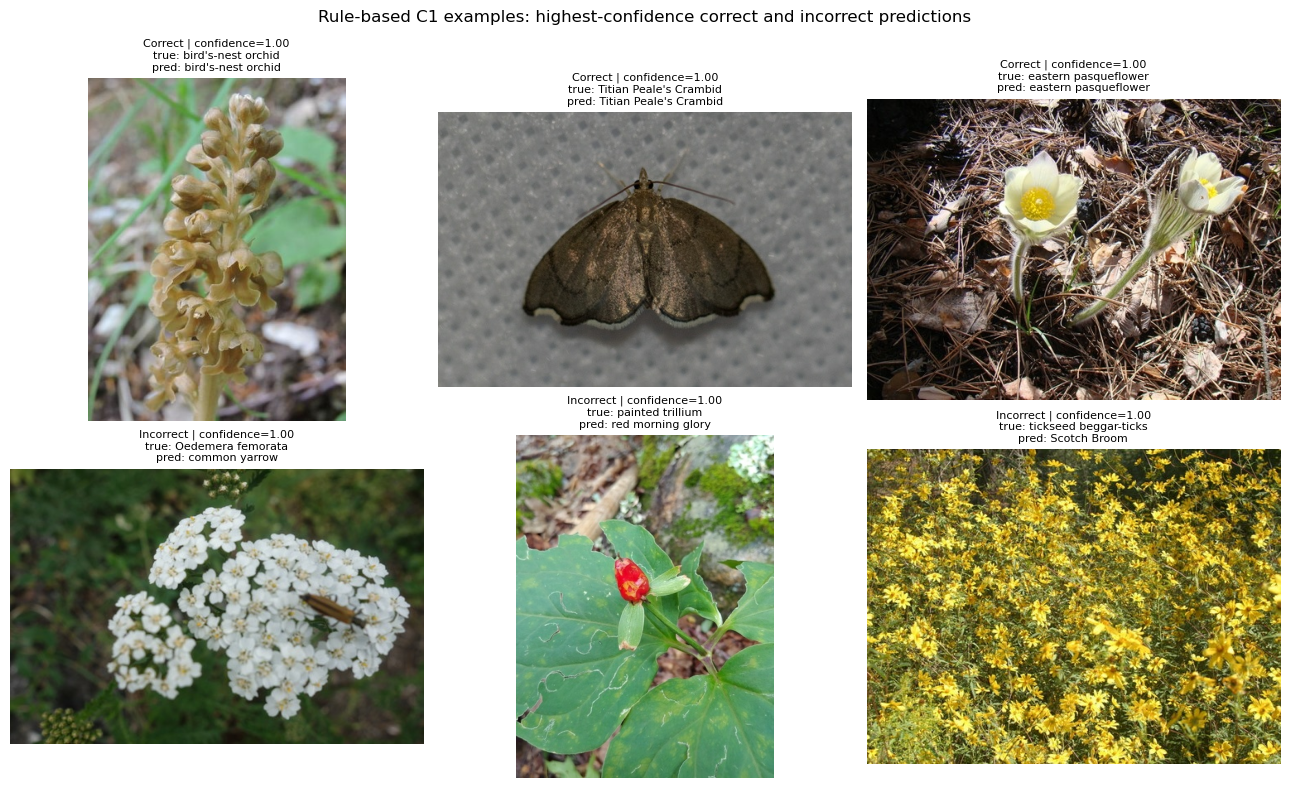

In [14]:
c1_predictions = formal_artifacts["C1: standard augmentation"]["predictions"].copy()
label_table = taxonomy.set_index("class_index")

def readable_label(class_index: int) -> str:
    row = label_table.loc[int(class_index)]
    common = row.get("common_name")
    if pd.notna(common) and str(common).strip():
        return str(common)
    return str(row["species"])

errors = c1_predictions[c1_predictions["is_correct"] == False].copy()
confusion_pairs = (
    errors.groupby(["true_class", "predicted_class"])
    .size()
    .reset_index(name="Count")
    .sort_values(["Count", "true_class", "predicted_class"], ascending=[False, True, True])
    .head(10)
)
confusion_pairs["True label"] = confusion_pairs["true_class"].map(readable_label)
confusion_pairs["Predicted label"] = confusion_pairs["predicted_class"].map(readable_label)
display(confusion_pairs[["True label", "Predicted label", "Count"]])

# Use a fixed confidence-based rule so examples are reproducible rather than hand-picked.
correct_examples = (
    c1_predictions[c1_predictions["is_correct"] == True]
    .sort_values("confidence", ascending=False)
    .head(3)
)
incorrect_examples = (
    c1_predictions[c1_predictions["is_correct"] == False]
    .sort_values("confidence", ascending=False)
    .head(3)
)
selected_examples = pd.concat(
    [correct_examples.assign(group="Correct"), incorrect_examples.assign(group="Incorrect")]
)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for axis, (_, row) in zip(axes.ravel(), selected_examples.iterrows()):
    with Image.open(DATA_ROOT / row["image_path"]) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(
        f"{row['group']} | confidence={row['confidence']:.2f}\n"
        f"true: {readable_label(row['true_class'])}\n"
        f"pred: {readable_label(row['predicted_class'])}",
        fontsize=8,
    )
    axis.axis("off")
fig.suptitle("Rule-based C1 examples: highest-confidence correct and incorrect predictions")
fig.tight_layout()
plt.show()

## 12. Live inference from the frozen C1 checkpoint

This cell loads the actual best C1 checkpoint, preprocesses one test image, and performs a new forward pass. The predicted class is compared with the corresponding row in the saved test predictions. Small confidence differences can occur across batch sizes or devices, but the predicted class must agree.

**Input:** the frozen C1 best checkpoint and one held-out test image.  
**Output:** a newly computed class/confidence pair that must agree with the corresponding saved predicted class.


,True class,Saved prediction,Live prediction,Saved confidence,Live confidence,Prediction matches,Checkpoint epoch
0,bird's-nest orchid,bird's-nest orchid,bird's-nest orchid,1.0,1.0,True,87


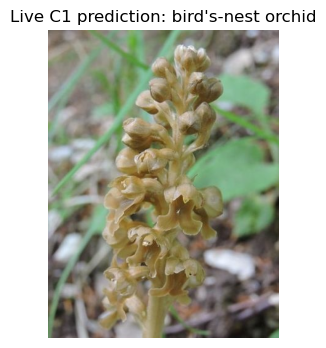

25624

In [15]:
# Run a fresh forward pass; do not reuse the probability stored in predictions_test.csv.
live_row = correct_examples.iloc[0]
c1_config = formal_artifacts["C1: standard augmentation"]["config"]
live_model = build_model(**c1_config["model"]).to(DEVICE)
live_checkpoint = torch.load(
    formal_artifacts["C1: standard augmentation"]["checkpoint_path"],
    map_location=DEVICE,
    weights_only=False,
)
live_model.load_state_dict(live_checkpoint["model"])
live_model.eval()

live_transform = build_transform(
    "eval",
    c1_config["data"]["image_size"],
    c1_config["data"]["resize_size"],
    False,
)
live_path = DATA_ROOT / live_row["image_path"]
with Image.open(live_path) as image:
    live_image = image.convert("RGB")
    live_tensor = live_transform(live_image).unsqueeze(0).to(DEVICE)

with torch.inference_mode(), torch.autocast(
    device_type=DEVICE.type, enabled=DEVICE.type == "cuda"
):
    live_logits = live_model(live_tensor)
live_probability = live_logits.float().softmax(dim=1)
live_prediction = int(live_logits.argmax(dim=1).item())
live_confidence = float(live_probability[0, live_prediction].item())

live_result = pd.DataFrame(
    [
        {
            "True class": readable_label(int(live_row["true_class"])),
            "Saved prediction": readable_label(int(live_row["predicted_class"])),
            "Live prediction": readable_label(live_prediction),
            "Saved confidence": float(live_row["confidence"]),
            "Live confidence": live_confidence,
            "Prediction matches": live_prediction == int(live_row["predicted_class"]),
            "Checkpoint epoch": int(live_checkpoint["epoch"]),
        }
    ]
)
display(live_result)
plt.figure(figsize=(5, 4))
plt.imshow(live_image)
plt.title(f"Live C1 prediction: {readable_label(live_prediction)}")
plt.axis("off")
plt.show()
assert live_prediction == int(live_row["predicted_class"])

del live_model, live_checkpoint, live_tensor, live_logits
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
gc.collect()

## 13. Interpretation and limitations

The controlled comparison shows that random resized cropping and horizontal flipping substantially improve the generalization of a scratch-trained ResNet-18 on this fine-grained 500-class task. The augmentation creates different views of the same organism and reduces overfitting to fixed image framing.

Top-1 and macro-F1 follow similar trends because every class has equal test support. They are still different metrics: Top-1 measures overall correct predictions, while macro-F1 averages the class-wise balance of precision and recall.

Limitations:

- only one seed (`9517`) was run, so the difference should not be described as statistically significant;
- C0 and C1 evaluate one architecture and one augmentation recipe;
- some errors may depend on background or context, which should be investigated by the Grad-CAM member;
- the test set was used only after checkpoint selection and should not be used for further tuning.

In [16]:
print(
    f"C0 test Top-1: {c0['Top-1 (%)']:.2f}% | "
    f"C1 test Top-1: {c1['Top-1 (%)']:.2f}% | "
    f"improvement: {delta.iloc[0]['Top-1 (%)']:.2f} percentage points"
)
print(
    f"C0 macro-F1: {c0['Macro-F1 (%)']:.2f}% | "
    f"C1 macro-F1: {c1['Macro-F1 (%)']:.2f}% | "
    f"improvement: {delta.iloc[0]['Macro-F1 (%)']:.2f} percentage points"
)
print("Notebook complete: smoke training, provenance checks, analysis, and live inference passed.")

C0 test Top-1: 21.62% | C1 test Top-1: 41.32% | improvement: 19.70 percentage points
C0 macro-F1: 21.42% | C1 macro-F1: 40.45% | improvement: 19.03 percentage points
Notebook complete: smoke training, provenance checks, analysis, and live inference passed.


## 14. Shared group evaluation (validation only)

Member A provides one common evaluator for all handcrafted and deep models. This interoperability stage exports the complete 500-class validation logits from the frozen C0 and C1 best checkpoints, then recomputes the group-standard Top-1, Top-5, macro precision, macro recall, macro F1, predictions, and confusion matrices.

**Input:** the unchanged C0/C1 `best.pt` checkpoints and the frozen `data_metadata/val.csv` manifest.  
**Output:** two `(5000, 500)` NPZ score files and standardized validation result directories under `outputs/shared_evaluation/`.

This is deterministic inference, not retraining. It does not access `test.csv`, change either checkpoint, or reconstruct missing scores from the earlier Top-5 CSV. Generated NPZ/result files are local artifacts and must be excluded from the final 40 MB source-code ZIP.

In [17]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

# Locate the project root whether Jupyter starts in the root or notebooks/ directory.
shared_project_root = next(
    candidate
    for candidate in (Path.cwd().resolve(), Path.cwd().resolve().parent)
    if (candidate / "data_metadata" / "val.csv").exists()
)
os.environ.setdefault(
    "MPLCONFIGDIR", str(shared_project_root / ".cache" / "matplotlib")
)
if str(shared_project_root) not in sys.path:
    sys.path.insert(0, str(shared_project_root))
from src.evaluation.evaluate_predictions import evaluate_scores, save_evaluation


class SharedValidationDataset(Dataset):
    """Read the frozen validation manifest without changing its row order."""

    def __init__(self, manifest, data_root, transform):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.data_root = Path(data_root)
        self.transform = transform

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, index):
        row = self.manifest.iloc[index]
        relative_path = str(row["image_path"])
        with Image.open(self.data_root / relative_path) as image:
            tensor = self.transform(image.convert("RGB"))
        return tensor, int(row["class_index"]), relative_path


def export_frozen_validation_scores(run_name, output_stem):
    """Export full logits and run A's evaluator without updating model parameters."""
    run_dir = shared_project_root / "outputs" / run_name
    checkpoint_path = run_dir / "checkpoints" / "best.pt"
    validation_manifest = pd.read_csv(
        shared_project_root / "data_metadata" / "val.csv",
        dtype={"image_id": str},
    )

    # These assertions make the assignment's 500-class/10-validation-images contract explicit.
    assert len(validation_manifest) == 5000
    assert validation_manifest["class_index"].nunique() == 500
    assert validation_manifest.groupby("class_index").size().eq(10).all()
    assert set(validation_manifest["split"].astype(str)) == {"val"}

    evaluation_transform = transforms.Compose(
        [
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            ),
        ]
    )
    dataset = SharedValidationDataset(
        validation_manifest,
        shared_project_root / "dataset_extracted",
        evaluation_transform,
    )
    # workers=0 avoids Windows/Jupyter multiprocessing ambiguity; timing measures forward passes only.
    loader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 500)
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    model.to(device).eval()

    # Warm up kernels without consuming or changing any validation result.
    warmup_images, _, _ = next(iter(loader))
    with torch.inference_mode(), torch.autocast(
        device_type=device.type, enabled=device.type == "cuda"
    ):
        model(warmup_images.to(device))
    if device.type == "cuda":
        torch.cuda.synchronize()

    logits_parts, label_parts, path_parts = [], [], []
    inference_seconds = 0.0
    with torch.inference_mode():
        for images, labels, paths in loader:
            images = images.to(device)
            if device.type == "cuda":
                torch.cuda.synchronize()
            started = time.perf_counter()
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                logits = model(images)
            if device.type == "cuda":
                torch.cuda.synchronize()
            inference_seconds += time.perf_counter() - started
            logits_parts.append(logits.float().cpu())
            label_parts.append(labels.to(torch.int64))
            path_parts.extend(str(path) for path in paths)

    scores = torch.cat(logits_parts).numpy().astype(np.float32, copy=False)
    true_labels = torch.cat(label_parts).numpy().astype(np.int64, copy=False)
    image_paths = np.asarray(path_parts, dtype=str)
    class_indices = np.arange(500, dtype=np.int64)

    # Verify exact alignment with the frozen CSV before sharing any score file.
    assert scores.shape == (5000, 500) and np.isfinite(scores).all()
    np.testing.assert_array_equal(
        true_labels, validation_manifest["class_index"].to_numpy(dtype=np.int64)
    )
    np.testing.assert_array_equal(
        image_paths, validation_manifest["image_path"].astype(str).to_numpy()
    )

    shared_output = shared_project_root / "outputs" / "shared_evaluation"
    shared_output.mkdir(parents=True, exist_ok=True)
    npz_path = shared_output / f"{output_stem}_validation_scores.npz"
    np.savez_compressed(
        npz_path,
        scores=scores,
        true_labels=true_labels,
        image_paths=image_paths,
        class_indices=class_indices,
    )
    # Reopen with pickle disabled to prove that A's loader can consume the archive safely.
    with np.load(npz_path, allow_pickle=False) as exported:
        assert exported["scores"].shape == (5000, 500)
        assert exported["image_paths"].dtype.kind in {"U", "S"}

    timing = json.loads((run_dir / "timing.json").read_text(encoding="utf-8"))
    result = evaluate_scores(
        scores,
        true_labels,
        class_indices,
        image_paths,
        inference_seconds=inference_seconds,
        training_seconds=float(timing["training_total_seconds"]),
    )
    result_dir = save_evaluation(
        result,
        shared_output / f"{output_stem}_validation",
        model_name=run_name,
        split="validation",
        input_path=npz_path,
        overwrite=True,
    )
    frozen_metrics = json.loads(
        (run_dir / "metrics_val.json").read_text(encoding="utf-8")
    )
    core_metric_pairs = {
        "top1_accuracy": "top1_accuracy",
        "macro_precision": "macro_precision",
        "macro_recall": "macro_recall",
        "macro_f1": "macro_f1",
    }
    max_core_difference = max(
        abs(result["metrics"][shared] - frozen_metrics[frozen])
        for shared, frozen in core_metric_pairs.items()
    )
    assert max_core_difference < 1e-6, f"Core metric mismatch: {max_core_difference}"

    # Compare Top-5 membership row by row because equal logits may straddle rank five.
    historical_predictions = pd.read_csv(run_dir / "predictions_val.csv")
    np.testing.assert_array_equal(
        historical_predictions["image_path"].astype(str).to_numpy(), image_paths
    )
    historical_top5 = np.asarray(
        historical_predictions["top5_classes"].map(json.loads).tolist(),
        dtype=np.int64,
    )
    historical_top5_correct = np.any(
        historical_top5 == true_labels[:, None], axis=1
    )
    shared_top5_correct = result["predictions"]["correct_top5"].to_numpy(dtype=bool)
    changed_top5_rows = np.flatnonzero(historical_top5_correct != shared_top5_correct)
    stable_ranking = np.argsort(-scores, axis=1, kind="stable")[:, :5]
    fifth_scores = scores[np.arange(len(scores)), stable_ranking[:, -1]]
    for row_index in changed_top5_rows:
        true_score = scores[row_index, true_labels[row_index]]
        assert true_score == fifth_scores[row_index], (
            f"Unexplained Top-5 difference at row {row_index}: "
            f"true score {true_score}, cutoff {fifth_scores[row_index]}"
        )
    expected_top5 = float(historical_top5_correct.mean())
    assert abs(expected_top5 - frozen_metrics["top5_accuracy"]) < 1e-6
    agreement_note = (
        "PASS"
        if len(changed_top5_rows) == 0
        else f"PASS ({len(changed_top5_rows)} Top-5 boundary tie)"
    )

    return {
        "Run": output_stem.upper(),
        "Scores shape": str(scores.shape),
        "Top-1 (%)": 100 * result["metrics"]["top1_accuracy"],
        "Shared Top-5 (%)": 100 * result["metrics"]["top5_accuracy"],
        "Historical Top-5 (%)": 100 * frozen_metrics["top5_accuracy"],
        "Top-5 boundary ties": len(changed_top5_rows),
        "Macro-F1 (%)": 100 * result["metrics"]["macro_f1"],
        "Inference (s)": inference_seconds,
        "Max core metric difference": max_core_difference,
        "Agreement": agreement_note,
        "NPZ": str(npz_path.relative_to(shared_project_root)),
        "Result directory": str(result_dir.relative_to(shared_project_root)),
    }


In [18]:
# Run validation-only score export for both graded scratch experiments.
shared_evaluation_rows = [
    export_frozen_validation_scores("c0_scratch_resnet18_noaug", "c0"),
    export_frozen_validation_scores("c1_scratch_resnet18_standard_aug", "c1"),
]
shared_evaluation_summary = pd.DataFrame(shared_evaluation_rows)
print(shared_evaluation_summary.to_string(index=False))
print(
    "Shared evaluation complete: two frozen validation checkpoints, "
    "5,000 images each, no training and no test access."
)


Run Scores shape  Top-1 (%)  Shared Top-5 (%)  Historical Top-5 (%)  Top-5 boundary ties  Macro-F1 (%)  Inference (s)  Max core metric difference                   Agreement                                                NPZ                        Result directory
 C0  (5000, 500)       21.9             43.38             43.380001                    0     22.107206       2.060900                3.218651e-09                        PASS outputs\shared_evaluation\c0_validation_scores.npz outputs\shared_evaluation\c0_validation
 C1  (5000, 500)       40.9             63.30             63.319999                    1     40.165463       2.093461                9.298325e-09 PASS (1 Top-5 boundary tie) outputs\shared_evaluation\c1_validation_scores.npz outputs\shared_evaluation\c1_validation
Shared evaluation complete: two frozen validation checkpoints, 5,000 images each, no training and no test access.
